# Validação dos resultados — Biocomputação neuronal (MCEQ 12576, PUC-Campinas)

## Para que serve este notebook
Ele reexecuta **do zero**, a partir do CSV público, todos os números que aparecem no rascunho do
artigo (`atividade.docx`) e confere se batem. É também o **pacote de reprodutibilidade** exigido no
roteiro (Seção 8): quem clonar o repositório e rodar este notebook deve obter os mesmos números do artigo.

## Pergunta e hipóteses (do protocolo)
- **Pergunta:** a acurácia de classificação de dígitos obtida a partir de sinais **reais** de culturas
  neuronais humanas supera a de um **controle aleatorizado** (`Random`)?
- **Δ** = acurácia Real − acurácia Random, calculada **por chip** (média das sessões do chip).
- **H0:** μΔ ≤ 0  **H1:** μΔ > 0 (unilateral)  **α = 0,05**
- **Tipo de estudo:** reanálise **observacional** de resultados já publicados. Não houve sorteio feito por
  nós, então nenhuma afirmação é causal. A hipótese **não foi pré-registrada** antes de inspecionar a
  base, por isso o artigo a declara **exploratória**.

## Roteiro do notebook
| Seção | O que faz | Vai para o artigo como |
|---|---|---|
| 0 | Configuração e função de checagem | — |
| 1 | Carrega os dados brutos | Método (base, proveniência) |
| 2 | Limpeza com regras declaradas | Método (limpeza) |
| 3 | Agrega sessões por chip | Método (unidade de análise) |
| 4 | Estatística descritiva | Resultados, Tabela 1 |
| 5 | Checa a normalidade das diferenças | Método (justificativa do teste) |
| 6 | Wilcoxon pareado (teste principal) | Resultados (p-valor, decisão) |
| 7 | Tamanho de efeito d_z e IC95% | Resultados |
| 8 | t pareado (sensibilidade) | Resultados (sensibilidade) |
| 9 | Figura 1 | Resultados, Figura 1 |
| 10 | Robustez às decisões de análise | Análises exploratórias |
| 11 | Lotes de gravação (pós-hoc) | Análises exploratórias + Ameaças |
| 12 | Resumo das checagens | — |

**Base:** `file_names.csv` do repositório
[Cortical-Labs/handwritten-digit-neural-cultures](https://github.com/Cortical-Labs/handwritten-digit-neural-cultures),
associado a Loeffler et al. (2026, preprint bioRxiv). Licença **CC BY-NC 4.0**.

## 0. Configuração

- Importa as bibliotecas: `pandas` (tabelas), `numpy` (contas), `scipy.stats` (testes) e `matplotlib` (gráficos).
- Define os caminhos e o **α = 0,05**, fixado antes da análise, como pede a aula 06.
- Cria a função **`confere(nome, obtido, esperado, tol)`**. Ela compara um valor calculado aqui com o
  valor escrito no rascunho, imprime `OK` ou `XX` e guarda o resultado para o resumo da seção 12.
  A tolerância `tol` cobre o arredondamento do texto: 0,005 aceita qualquer valor que arredonde para os
  2 decimais citados.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# Raiz do repositório: funciona tanto rodando da raiz quanto de uma subpasta
RAIZ = Path.cwd() if (Path.cwd() / "dados").exists() else Path.cwd().parent
BRUTO = RAIZ / "dados/brutos/file_names.csv"
URL = "https://raw.githubusercontent.com/Cortical-Labs/handwritten-digit-neural-cultures/main/file_names.csv"
SHA256_ESPERADO = "c5e762bd1f51b47762c0f4ba377698ab5525cc56b6f86ee2c881a6b9b4f52d65"  # versão de 12/11/2026
ALPHA = 0.05  # nível de significância, fixado antes da análise

(RAIZ / "dados/limpos").mkdir(parents=True, exist_ok=True)
(RAIZ / "figuras").mkdir(exist_ok=True)

checagens = []
def confere(nome, obtido, esperado, tol):
    """Compara um número recalculado com o valor citado no rascunho do artigo."""
    ok = abs(obtido - esperado) <= tol
    checagens.append({"item": nome, "rascunho": esperado, "obtido": obtido, "ok": ok})
    print(f"{'OK ' if ok else 'XX '} {nome}: obtido={obtido:.6g} | rascunho={esperado:.6g}")

print("scipy", __import__("scipy").__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scipy 1.18.1 | pandas 3.1.1 | numpy 2.5.4


## 1. Dados brutos

**O que faz:** lê o CSV original, sem nenhuma edição manual. Se o arquivo não existir, baixa do GitHub.

**Proveniência:** o **SHA-256** é uma "impressão digital" do arquivo. Se a Cortical Labs alterar o CSV no
GitHub, o hash muda e o notebook avisa. Assim fica registrado exatamente qual versão dos dados usamos.

**Colunas que importam** (documentadas no README do repositório de origem):
| Coluna | Significado |
|---|---|
| `Chip ID` | Identificador físico do chip (MEA). Um chip pode ter várias sessões |
| `Cell Type` | Tipo de cultura: PDMS, Monolayer, Organoid (± Hippo); ou **controles** sem neurônio (`Saline`, `SDK Random Spikes`) |
| `Num Spikes` | Número de disparos elétricos (spikes) registrados na sessão |
| `Real` | Acurácia (proporção 0–1) do decodificador treinado nas respostas neuronais reais, na tarefa MNIST espaço-temporal |
| `Random` | Acurácia do mesmo pipeline com dados aleatorizados: o **controle pareado** |
| `Date` | Data/hora da sessão |

As demais colunas (`Real with Stim`, `Biased Decoder` etc.) são variantes de decodificação que não fazem
parte da nossa hipótese e **não são usadas**, para evitar testes múltiplos.

**Como ler a saída:** 52 linhas no total, com a contagem de sessões por tipo de cultura.

In [2]:
if not BRUTO.exists():
    BRUTO.parent.mkdir(parents=True, exist_ok=True)
    import urllib.request; urllib.request.urlretrieve(URL, BRUTO)

sha = hashlib.sha256(BRUTO.read_bytes()).hexdigest()
print("SHA-256:", sha)
print("mesma versão usada no artigo" if sha == SHA256_ESPERADO else "ATENÇÃO: o arquivo mudou desde a análise!")

bruto = pd.read_csv(BRUTO)
print("dimensões (linhas, colunas):", bruto.shape)
confere("linhas no CSV", len(bruto), 52, 0)
bruto["Cell Type"].value_counts()

SHA-256: c5e762bd1f51b47762c0f4ba377698ab5525cc56b6f86ee2c881a6b9b4f52d65
mesma versão usada no artigo
dimensões (linhas, colunas): (52, 15)
OK  linhas no CSV: obtido=52 | rascunho=52


Cell Type
PDMS                 23
Monolayer (Hippo)     8
Organoid (Hippo)      5
PDMS (Hippo)          5
Organoid              3
SDK Random Spikes     3
Saline                3
Monolayer             2
Name: count, dtype: int64

## 2. Limpeza (regras declaradas no Método)

**Regras**, definidas antes de rodar o teste e todas relatadas no artigo:
1. **Remover os controles sem neurônios** — `SDK Random Spikes` (3 sessões, spikes simulados por software)
   e `Saline` (3 sessões, só solução salina). Eles não são culturas biológicas, então não entram na
   comparação. Na seção 10 eles são usados para checar se o decodificador fica no acaso sem neurônios.
2. **Remover sessões com `Num Spikes < 500`** — o artigo de origem usa esse limite mínimo de atividade.
   Apenas 1 sessão cai aqui (469 spikes).

**Conversão:** `Real` e `Random` vêm como proporção (0,353) e passam para **percentual** (35,3%).

**Saída gravada:** `dados/limpos/sessoes_limpas.csv`, gerado pelo script e nunca editado à mão.

**Como ler a saída:** 6 controles e 1 sessão de baixa atividade removidos, sobrando **45 sessões de 26 chips**.

In [3]:
CONTROLES = ["SDK Random Spikes", "Saline"]
eh_controle = bruto["Cell Type"].isin(CONTROLES)                   # regra 1
poucos_spikes = ~eh_controle & (bruto["Num Spikes"] < 500)         # regra 2

print("controles removidos:", eh_controle.sum())
print("sessões < 500 spikes removidas:", poucos_spikes.sum())
display(bruto.loc[poucos_spikes, ["Chip ID", "Cell Type", "Num Spikes", "Real", "Random"]])

limpo = bruto.loc[~eh_controle & ~poucos_spikes].copy()
limpo[["Real", "Random"]] *= 100   # proporção -> %
limpo.to_csv(RAIZ / "dados/limpos/sessoes_limpas.csv", index=False)

confere("controles excluídos", eh_controle.sum(), 6, 0)
confere("sessões <500 excluídas", poucos_spikes.sum(), 1, 0)
confere("sessões biológicas", len(limpo), 45, 0)
confere("chips únicos", limpo["Chip ID"].nunique(), 26, 0)

controles removidos: 6
sessões < 500 spikes removidas: 1


,Chip ID,Cell Type,Num Spikes,Real,Random
0,MCS_1_43609_00001,Organoid,469.0,0.353,0.123


OK  controles excluídos: obtido=6 | rascunho=6
OK  sessões <500 excluídas: obtido=1 | rascunho=1
OK  sessões biológicas: obtido=45 | rascunho=45
OK  chips únicos: obtido=26 | rascunho=26


## 3. Agregação por chip (unidade de análise)

**Problema:** alguns chips foram gravados várias vezes (até 4 sessões). Se cada sessão contasse como uma
observação independente, os chips mais gravados pesariam mais e o *n* ficaria inflado (45 em vez de 26).
Isso se chama **pseudorreplicação**.

**Solução:** a **unidade de análise é o chip**. Para cada chip calculamos a média de `Real` e de `Random`
entre as suas sessões, e a diferença **`Dif` = Real − Random**.

**Desenho:** cada chip tem as duas condições (Real e Random), então o desenho é **pareado**. Cada chip é
um **bloco**, como os *runners* da aula 07. A análise usa as **diferenças dentro do chip**, o que remove a
variação entre chips.

**Saída gravada:** `dados/limpos/por_chip.csv`.

**Como ler a saída:** nenhum chip mistura tipos de cultura; 16 chips têm 1 sessão e 10 chips têm de 2 a 4.
A tabela mostra os 5 chips com menor diferença.

In [4]:
por_chip = (limpo.groupby("Chip ID")
            .agg(Real=("Real", "mean"), Random=("Random", "mean"),
                 sessoes=("Real", "size"), tipo=("Cell Type", "first"))
            .reset_index())
por_chip["Dif"] = por_chip["Real"] - por_chip["Random"]   # Δ por chip, em pontos percentuais (pp)
por_chip.to_csv(RAIZ / "dados/limpos/por_chip.csv", index=False)

# sanidade: um mesmo chip aparece com mais de um tipo de cultura?
print("chips com >1 tipo de cultura:", (limpo.groupby("Chip ID")["Cell Type"].nunique() > 1).sum())
print(por_chip["sessoes"].value_counts().sort_index().rename("chips por nº de sessões"))
por_chip.sort_values("Dif").head()

chips com >1 tipo de cultura: 0
sessoes
1    16
2     4
3     3
4     3
Name: chips por nº de sessões, dtype: int64


,Chip ID,Real,Random,sessoes,tipo,Dif
10,MCS_1_42758_00001,30.8,12.100,1,Organoid,18.700
1,MCS_1_42461_00001,34.6,12.300,4,Monolayer (Hippo),22.300
15,MCS_1_43492_00001,34.5,12.125,4,PDMS (Hippo),22.375
19,MCS_1_43616_00001,34.8,12.100,1,Organoid,22.700
18,MCS_1_43615_00001,34.7,12.000,1,Organoid (Hippo),22.700


## 4. Estatística descritiva (Tabela 1 do artigo)

**O que faz:** resume as 26 médias por chip, com número de chips (`count`), média, desvio padrão (`std`),
mediana, mínimo e máximo, para Real, Random e para a diferença.

**Unidades:** Real e Random em **%** (acurácia). Desvios e diferenças em **pp** (pontos percentuais).
Uma diferença de 30% para 40% é de 10 pp.

**Como ler:**
- **Acaso** com 10 dígitos é 10%. O controle Random fica perto disso (~11,5%) e com pouca dispersão.
- **Real** tem média ~44% e dispersão bem maior entre chips (DP ~10 pp).
- **Todos os 26 chips** têm Real > Random. A menor diferença é 18,7 pp.
- Na linha `Dif`, a média (32,6) é maior que a mediana (27,4). É um primeiro sinal de **assimetria**,
  investigada na próxima seção.

In [5]:
desc = por_chip[["Real", "Random", "Dif"]].agg(["count", "mean", "std", "median", "min", "max"]).T
display(desc.round(2))

confere("média Real (%)", desc.loc["Real", "mean"], 44.07, 0.005)
confere("DP Real (pp)", desc.loc["Real", "std"], 10.32, 0.005)
confere("média Random (%)", desc.loc["Random", "mean"], 11.47, 0.005)
confere("DP Random (pp)", desc.loc["Random", "std"], 1.04, 0.005)
confere("chips com Real > Random", (por_chip["Dif"] > 0).sum(), 26, 0)

,count,mean,std,median,min,max
Real,26.0,44.07,10.32,39.69,30.8,66.70
Random,26.0,11.47,1.04,12.11,9.9,12.35
Dif,26.0,32.60,11.15,27.43,18.7,56.70


OK  média Real (%): obtido=44.0657 | rascunho=44.07
OK  DP Real (pp): obtido=10.3228 | rascunho=10.32
OK  média Random (%): obtido=11.466 | rascunho=11.47
OK  DP Random (pp): obtido=1.04267 | rascunho=1.04
OK  chips com Real > Random: obtido=26 | rascunho=26


## 5. Pressupostos: as diferenças são normais?

**Por que importa:** o **t pareado** supõe que as diferenças por chip têm distribuição aproximadamente
normal. Quando isso falha (assimetria ou outliers), a aula 07 recomenda o **Wilcoxon pareado**, que é não
paramétrico e trabalha com os **postos** (a ordem) das diferenças em vez dos valores.

**O que faz:**
- **Shapiro-Wilk:** testa H0 = "as diferenças são normais". Um *p* pequeno indica normalidade violada.
- **Assimetria (skew):** 0 é simétrico; valores positivos indicam cauda para a direita.
- **Histograma:** mostra o formato da distribuição.
- **Gráfico Q-Q:** se os pontos seguem a reta vermelha, a distribuição é normal. Desvios sistemáticos
  indicam que não é.

**Como ler:** Shapiro p ≈ 0,0005 < 0,05, então a **normalidade foi violada**. Isso **justifica o Wilcoxon**
como teste principal. O histograma mostra ainda que as diferenças formam **dois grupos** (~20–35 pp e
~43–57 pp); isso é investigado na seção 11.

Shapiro-Wilk nas diferenças: W=0.824, p=0.0005
assimetria=0.89


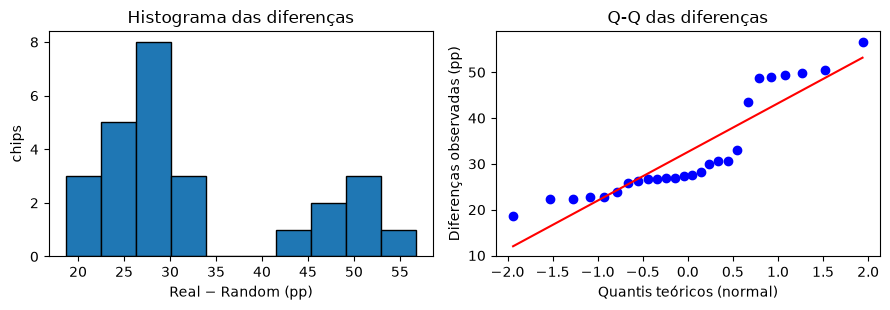

In [6]:
d = por_chip["Dif"].to_numpy()
sw = stats.shapiro(d)
print(f"Shapiro-Wilk nas diferenças: W={sw.statistic:.3f}, p={sw.pvalue:.4f}")
print(f"assimetria={stats.skew(d):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].hist(d, bins=10, edgecolor="k")
ax[0].set_xlabel("Real − Random (pp)"); ax[0].set_ylabel("chips"); ax[0].set_title("Histograma das diferenças")
stats.probplot(d, plot=ax[1]); ax[1].set_title("Q-Q das diferenças")
ax[1].set_xlabel("Quantis teóricos (normal)"); ax[1].set_ylabel("Diferenças observadas (pp)")
plt.tight_layout(); plt.show()

## 6. Teste principal: Wilcoxon pareado unilateral

**Por que este teste:** o desenho é **pareado** (Real e Random no mesmo chip) e as diferenças **não são
normais** (seção 5). Pelo guia de decisão da aula 07, pareado com normalidade violada leva ao
`stats.wilcoxon`. É **unilateral** (`alternative="greater"`) porque H1 é Real > Random.

**Como funciona:** ordena as diferenças |Δ| do menor para o maior e dá postos 1, 2, …, 26. **W** é a soma
dos postos das diferenças **positivas**. Se H0 fosse verdadeira, positivas e negativas se dividiriam ao
acaso e W ficaria perto de 175,5 (metade do máximo).

**Três formas de calcular o p-valor:**
- **Exato:** enumera todas as combinações de sinais. Como as 26 diferenças são positivas, W = 351 (o
  máximo) e p = 1/2²⁶ ≈ 1,5×10⁻⁸.
- **Assintótico:** usa a aproximação normal, com correção para empates. Dá ≈ 4,14×10⁻⁶.
- **Automático do SciPy:** escolhe o assintótico porque há **empates** nas diferenças (dois chips com
  22,7 pp). Com empates, o exato não é estritamente válido.

**O rascunho usa o assintótico** (4,15×10⁻⁶, que arredondado corretamente é **4,14×10⁻⁶**). Sugestão de
texto: *"p < 0,0001 (aproximação normal; há empates)"*.

**Decisão:** em qualquer das três formas, p ≪ α = 0,05, então **rejeitamos H0**.

In [7]:
w_exato = stats.wilcoxon(por_chip["Real"], por_chip["Random"], alternative="greater", method="exact")
w_assint = stats.wilcoxon(por_chip["Real"], por_chip["Random"], alternative="greater", method="asymptotic")
w_auto = stats.wilcoxon(por_chip["Real"], por_chip["Random"], alternative="greater")
n = len(d)
print(f"n = {n} chips (pares)")
print(f"W (soma dos postos positivos) = {w_exato.statistic:.0f}  (máximo possível = n(n+1)/2 = {n*(n+1)//2})")
print(f"p exato        = {w_exato.pvalue:.3e}   (= 1/2^26 = {1/2**26:.3e})")
print(f"p assintótico  = {w_assint.pvalue:.3e}")
print(f"p 'auto' scipy = {w_auto.pvalue:.3e}")

confere("W de Wilcoxon", w_exato.statistic, 351, 0)
confere("p assintótico (rascunho)", w_assint.pvalue, 0.00000415, 0.00000001)
print("Decisão (α = 0,05): rejeita H0" if w_auto.pvalue <= ALPHA else "Decisão (α = 0,05): não rejeita H0")

n = 26 chips (pares)
W (soma dos postos positivos) = 351  (máximo possível = n(n+1)/2 = 351)
p exato        = 1.490e-08   (= 1/2^26 = 1.490e-08)
p assintótico  = 4.142e-06
p 'auto' scipy = 4.142e-06
OK  W de Wilcoxon: obtido=351 | rascunho=351
OK  p assintótico (rascunho): obtido=4.1421e-06 | rascunho=4.15e-06
Decisão (α = 0,05): rejeita H0


## 7. Tamanho de efeito (d_z) e intervalo de confiança de 95%

O p-valor diz **se** existe diferença. O **tamanho de efeito** e o **IC** dizem **quanto** (aula 06:
"relato mínimo = descritiva + p-valor + IC + tamanho de efeito").

**Fórmulas** (formulário da aula 07, teste pareado):
- Diferença média: d̄ = média de Δ
- Desvio das diferenças: s_d. Erro padrão: EP = s_d / √n
- **IC95%** = d̄ ± t₀,₉₇₅;₂₅ × EP, com t crítico de 2,060 para 25 graus de liberdade
- **d_z de Cohen** = d̄ / s_d, a versão pareada do *d*. Referências de Cohen: 0,2 pequeno, 0,5 médio,
  0,8 grande.

**Como ler:**
- Em média, a acurácia Real supera o controle em **32,6 pp**, com IC95% de **28,1 a 37,1 pp**. O
  intervalo está longe de zero, então a estimativa é precisa nesta amostra.
- **d_z = 2,92** é um efeito muito grande: a diferença média equivale a quase 3 desvios padrão das
  diferenças.
- Ressalva: o IC usa o t de Student, que supõe normalidade, e essa suposição falhou na seção 5. Com
  efeito desse tamanho a conclusão não muda, mas vale citar.

A segunda linha confere o IC manual com a função pronta do SciPy (`ttest_rel(...).confidence_interval`).

In [8]:
media_d, dp_d = d.mean(), d.std(ddof=1)      # ddof=1: desvio padrão amostral (divide por n-1)
dz = media_d / dp_d                            # d_z de Cohen (pareado)
ep = dp_d / np.sqrt(n)                         # erro padrão da diferença média
tcrit = stats.t.ppf(0.975, n - 1)              # t crítico bilateral 95%, gl = n-1
ic = (media_d - tcrit * ep, media_d + tcrit * ep)
print(f"diferença média = {media_d:.2f} pp | DP = {dp_d:.2f} | EP = {ep:.2f} | t_crit = {tcrit:.3f}")
print(f"IC95% = [{ic[0]:.2f}; {ic[1]:.2f}] pp | d_z = {dz:.2f}")

ic_scipy = stats.ttest_rel(por_chip["Real"], por_chip["Random"]).confidence_interval(0.95)
print(f"IC95% (scipy ttest_rel) = [{ic_scipy.low:.2f}; {ic_scipy.high:.2f}]")

confere("diferença média (pp)", media_d, 32.60, 0.005)
confere("IC95% inferior", ic[0], 28.10, 0.005)
confere("IC95% superior", ic[1], 37.10, 0.005)
confere("d_z de Cohen", dz, 2.92, 0.005)

diferença média = 32.60 pp | DP = 11.15 | EP = 2.19 | t_crit = 2.060
IC95% = [28.10; 37.10] pp | d_z = 2.92
IC95% (scipy ttest_rel) = [28.10; 37.10]
OK  diferença média (pp): obtido=32.5997 | rascunho=32.6
OK  IC95% inferior: obtido=28.0961 | rascunho=28.1
OK  IC95% superior: obtido=37.1033 | rascunho=37.1
OK  d_z de Cohen: obtido=2.92373 | rascunho=2.92


## 8. Teste alternativo previsto no protocolo: t pareado (sensibilidade)

**Por que rodar:** o protocolo definiu o t pareado **antes** da análise como teste de **sensibilidade**,
para ver se a conclusão depende da escolha do teste. Ele é relatado **separadamente** e **não substitui**
o Wilcoxon. Trocar de teste depois de ver o p-valor seria p-hacking.

**Como ler:** t = 14,91 com 25 graus de liberdade e p ≈ 3×10⁻¹⁴. Os dois testes concordam: rejeita-se H0.
Como a normalidade foi violada, o t pareado é menos confiável aqui, e por isso fica como sensibilidade.

In [9]:
t_par = stats.ttest_rel(por_chip["Real"], por_chip["Random"], alternative="greater")
print(f"t pareado: t={t_par.statistic:.2f}, gl={t_par.df}, p={t_par.pvalue:.3e}")

t pareado: t=14.91, gl=25, p=3.012e-14


## 9. Figura 1: pares por chip

**O que mostra:** cada **linha cinza** liga o Random e o Real do **mesmo chip**, que é a visualização
natural do desenho pareado (como o gráfico dos *runners* da aula 07). O **quadrado preto** é a média, com
barra de **IC95%**. A **linha vermelha tracejada** marca o acaso (10%).

**Boas práticas atendidas** (roteiro, Seção 9): eixo Y começa em **zero**, eixos com rótulo e unidade, a
dispersão aparece (todos os pontos) e há legenda.

**Como ler:** todas as linhas sobem, ou seja, 26 de 26 chips ficam acima do controle. O controle fica
colado no acaso, e o Real varia bastante entre chips (~31% a ~67%).

**Saída gravada:** `figuras/figura1_pares.png` (300 dpi, pronta para o template).

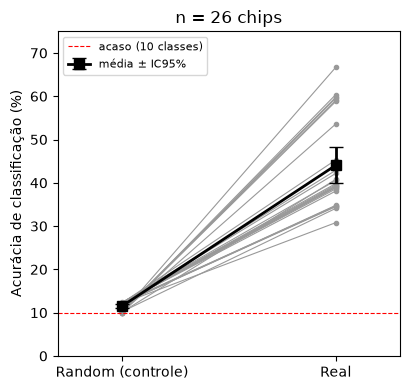

In [10]:
fig, ax = plt.subplots(figsize=(4.2, 4))
for _, r in por_chip.iterrows():                       # uma linha por chip
    ax.plot([0, 1], [r["Random"], r["Real"]], color="0.6", lw=0.8, marker="o", ms=3)
ax.errorbar([0, 1], [por_chip["Random"].mean(), por_chip["Real"].mean()],
            yerr=[stats.t.ppf(.975, n-1) * por_chip[c].std(ddof=1) / np.sqrt(n) for c in ["Random", "Real"]],
            color="k", lw=2, marker="s", ms=7, capsize=5, label="média ± IC95%")
ax.axhline(10, ls="--", color="r", lw=0.8, label="acaso (10 classes)")
ax.set_xticks([0, 1], ["Random (controle)", "Real"])
ax.set_xlim(-0.3, 1.3); ax.set_ylim(0, 75)
ax.set_ylabel("Acurácia de classificação (%)")
ax.set_title(f"n = {n} chips")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
fig.savefig(RAIZ / "figuras/figura1_pares.png", dpi=300)
plt.show()

## 10. Análises exploratórias: robustez às decisões de análise

> **Exploratório:** nada desta seção estava no protocolo. Se for usado no artigo, deve ir na subseção
> **"Análises exploratórias"** (roteiro, Seção 9).

**Pergunta:** a conclusão depende de alguma decisão que tomamos na limpeza ou na agregação? Repetimos o
Wilcoxon variando uma decisão por vez:
| Variante | Decisão alterada |
|---|---|
| principal: média por chip | nenhuma (referência) |
| mediana por chip | agregar sessões pela mediana em vez da média |
| sessão como unidade | ignorar o chip e usar as 45 sessões (pseudorreplicação, mostrada só para comparação) |
| mantendo sessão de 469 spikes | não aplicar a regra dos 500 spikes |

**Como ler:** em todas as variantes, 100% dos pares ficam com Real > Random, e d_z fica entre 2,9 e 3,1.
A conclusão **não depende** dessas escolhas.

In [11]:
def resumo(df, rotulo):
    dd = (df["Real"] - df["Random"]).to_numpy()
    w = stats.wilcoxon(df["Real"], df["Random"], alternative="greater")
    return {"análise": rotulo, "n": len(dd), "dif média (pp)": dd.mean(), "d_z": dd.mean()/dd.std(ddof=1),
            "p Wilcoxon": w.pvalue, "pares Real>Random": int((dd > 0).sum())}

com_469 = bruto.loc[~eh_controle].copy(); com_469[["Real", "Random"]] *= 100
chip_com_469 = com_469.groupby("Chip ID")[["Real", "Random"]].mean()
chip_mediana = limpo.groupby("Chip ID")[["Real", "Random"]].median()

robustez = pd.DataFrame([
    resumo(por_chip, "principal: média por chip"),
    resumo(chip_mediana, "mediana por chip"),
    resumo(limpo, "sessão como unidade (pseudorreplicação)"),
    resumo(chip_com_469, "mantendo sessão de 469 spikes"),
])
display(robustez.style.format({"p Wilcoxon": "{:.2e}"}, precision=2))

,análise,n,dif média (pp),d_z,p Wilcoxon,pares Real>Random
0,principal: média por chip,26,32.60,2.92,4.14e-06,26
1,mediana por chip,26,32.76,2.97,4.14e-06,26
2,sessão como unidade (pseudorreplicação),45,30.29,3.11,2.59e-09,45
3,mantendo sessão de 469 spikes,27,32.24,2.91,2.80e-06,27


**Controles sem neurônios (validade de construção).** Se o decodificador "acertasse" mesmo sem
neurônios, a acurácia Real poderia ser um artefato do pipeline e não um sinal biológico. Nos controles
`Saline` e `SDK Random Spikes`, a acurácia Real fica **perto do acaso** (~10–11%), o que ajuda a afastar
essa hipótese. Atenção: são só 3 sessões de cada, então isso não elimina a possibilidade de artefatos de
estímulo citados por Loeffler et al.

In [12]:
ctrl = bruto.loc[eh_controle, ["Cell Type", "Real", "Random"]].copy()
ctrl[["Real", "Random"]] *= 100
ctrl.groupby("Cell Type").agg(["mean", "count"]).round(2)

Real       Random      
                    mean count   mean count
Cell Type                                  
SDK Random Spikes   9.67     3  10.23     3
Saline             11.43     3  10.00     3

## 11. Análise exploratória: lotes de gravação (pós-hoc)

> **Exploratória, não confirmatória.** Este recorte surgiu **depois** de olhar o histograma da seção 5,
> que mostrou diferenças **bimodais**. Não estava no protocolo e **não substitui** H0/H1. Ele serve para
> **descrever uma possível variável de confusão**, não para testar uma nova hipótese. Apresentá-lo como
> hipótese prévia seria **HARKing**. Testes adicionais: 2 (um Wilcoxon por lote), relatados sem correção
> e só como descrição.

**Definição de lote** pela data da sessão:
- **nov–dez/2024:** chips com sufixo `_00001`
- **mar/2025:** chips com sufixo `_00002`

Nenhum chip aparece nos dois lotes.

**O que a tabela mostra por lote:** número de chips e sessões, médias de Real e Random, diferença média
com DP e IC95%, d_z, menor diferença, quantos chips ficam acima do controle e o p do Wilcoxon.

In [13]:
limpo["lote"] = np.where(pd.to_datetime(limpo["Date"].str[:10]) >= "2025-01-01", "mar/2025", "nov–dez/2024")
print("chips com sessões em mais de um lote:", (limpo.groupby("Chip ID")["lote"].nunique() > 1).sum())

por_chip = por_chip.merge(limpo.groupby("Chip ID")["lote"].first(), on="Chip ID")
LOTES = ["nov–dez/2024", "mar/2025"]

linhas = []
for lote in LOTES:
    g = por_chip[por_chip["lote"] == lote]
    dd = g["Dif"].to_numpy(); k = len(dd)
    ep_l = dd.std(ddof=1) / np.sqrt(k); tc = stats.t.ppf(0.975, k - 1)
    w = stats.wilcoxon(g["Real"], g["Random"], alternative="greater")
    linhas.append({"lote": lote, "chips": k, "sessões": int(g["sessoes"].sum()),
                   "Real (%)": g["Real"].mean(), "Random (%)": g["Random"].mean(),
                   "dif média (pp)": dd.mean(), "DP dif": dd.std(ddof=1),
                   "IC95% inf": dd.mean() - tc * ep_l, "IC95% sup": dd.mean() + tc * ep_l,
                   "d_z": dd.mean() / dd.std(ddof=1), "menor dif": dd.min(),
                   "Real>Random": f"{(dd > 0).sum()}/{k}", "p Wilcoxon": w.pvalue})
por_lote = pd.DataFrame(linhas).set_index("lote")
display(por_lote.style.format({"p Wilcoxon": "{:.2e}"}, precision=2))

chips com sessões em mais de um lote: 0


,chips,sessões,Real (%),Random (%),dif média (pp),DP dif,IC95% inf,IC95% sup,d_z,menor dif,Real>Random,p Wilcoxon
lote,,,,,,,,,,,,
nov–dez/2024,17,36,38.40,12.21,26.19,3.55,24.37,28.02,7.38,18.70,17/17,1.46e-04
mar/2025,9,9,54.77,10.07,44.70,10.55,36.59,52.81,4.24,23.90,9/9,1.95e-03


**Confundimento.** O lote coincide com outros fatores? A tabela cruzada mostra que mar/2025 tem
**só chips PDMS**, enquanto nov–dez/2024 inclui todas as arquiteturas. Além disso, o próprio **controle
Random** muda de nível entre os lotes (~12,2% contra ~10,1%, sem sobreposição). Isso sugere que a
configuração da tarefa ou do decodificador também mudou. Este bloco é só descritivo, sem teste.

In [14]:
print("Tipo de cultura × lote (nº de chips):")
display(pd.crosstab(por_chip["tipo"], por_chip["lote"])[LOTES])
print("Random (controle) por lote:")
display(por_chip.groupby("lote")["Random"].describe()[["count", "mean", "std", "min", "max"]].loc[LOTES].round(2))

Tipo de cultura × lote (nº de chips):


lote,nov–dez/2024,mar/2025
tipo,,
Monolayer,1,0
Monolayer (Hippo),2,0
Organoid,2,0
Organoid (Hippo),4,0
PDMS,7,8
PDMS (Hippo),1,1


Random (controle) por lote:


,count,mean,std,min,max
lote,,,,,
nov–dez/2024,17.0,12.21,0.1,12.0,12.35
mar/2025,9.0,10.07,0.1,9.9,10.20


**Figura exploratória** (`figuras/exploratoria_lotes.png`):
- **Esquerda:** os mesmos pares da Figura 1, coloridos por lote. As linhas vermelhas (mar/2025) chegam
  mais alto e partem de um controle ligeiramente mais baixo.
- **Direita:** histograma das diferenças, com as cores empilhadas por lote. As linhas tracejadas são as
  médias de cada lote; a pontilhada preta é a média geral (32,6 pp), que cai **entre** os dois grupos.

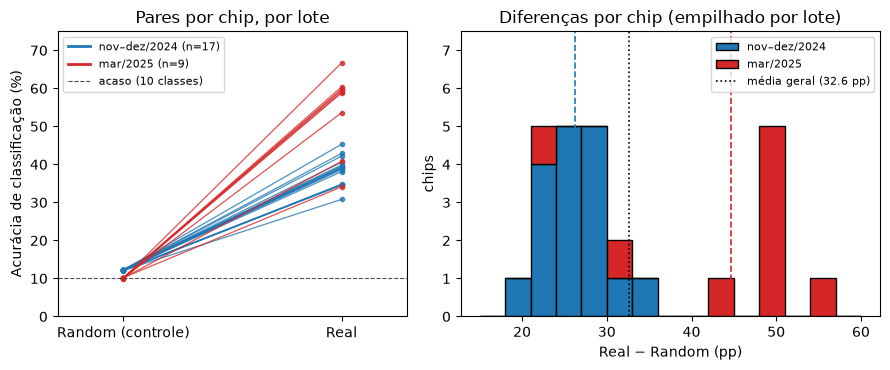

In [15]:
CORES = {"nov–dez/2024": "#1f77b4", "mar/2025": "#d62728"}
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8), gridspec_kw={"width_ratios": [1, 1.2]})

for _, r in por_chip.iterrows():
    ax[0].plot([0, 1], [r["Random"], r["Real"]], color=CORES[r["lote"]], lw=0.9, marker="o", ms=3, alpha=0.8)
for lote in LOTES:
    ax[0].plot([], [], color=CORES[lote], lw=2, label=f"{lote} (n={int((por_chip['lote'] == lote).sum())})")
ax[0].axhline(10, ls="--", color="0.3", lw=0.8, label="acaso (10 classes)")
ax[0].set_xticks([0, 1], ["Random (controle)", "Real"]); ax[0].set_xlim(-0.3, 1.3); ax[0].set_ylim(0, 75)
ax[0].set_ylabel("Acurácia de classificação (%)"); ax[0].legend(fontsize=8, loc="upper left")
ax[0].set_title("Pares por chip, por lote")

bins = np.arange(15, 61, 3)
ax[1].hist([por_chip.loc[por_chip["lote"] == l, "Dif"] for l in LOTES], bins=bins, stacked=True,
           color=[CORES[l] for l in LOTES], edgecolor="k", label=LOTES)
for lote in LOTES:
    ax[1].axvline(por_lote.loc[lote, "dif média (pp)"], color=CORES[lote], ls="--", lw=1.2)
ax[1].axvline(d.mean(), color="k", ls=":", lw=1.2, label=f"média geral ({d.mean():.1f} pp)")
ax[1].set_xlabel("Real − Random (pp)"); ax[1].set_ylabel("chips"); ax[1].set_ylim(0, 7.5)
ax[1].legend(fontsize=8, loc="upper right")
ax[1].set_title("Diferenças por chip (empilhado por lote)")

plt.tight_layout()
fig.savefig(RAIZ / "figuras/exploratoria_lotes.png", dpi=300)
plt.show()

**Leitura (para Ameaças à validade e Análises exploratórias):**
- **Conclusão preservada:** o efeito aparece **nos dois lotes**, com todos os chips acima do controle.
  A decisão sobre H0 não depende do lote.
- **Magnitude heterogênea:** ~26 pp em nov–dez/2024 contra ~45 pp em mar/2025, com ICs que não se
  sobrepõem. A média geral (32,6 pp) não descreve bem nenhum dos dois regimes.
- **Validade interna (confundimento):** lote, arquitetura (mar/2025 só tem PDMS) e nível do controle
  variam juntos. Os dados não permitem atribuir a diferença de magnitude a nenhum desses fatores.
- **Validade de conclusão:** a bimodalidade reforça a escolha de um teste não paramétrico.
- **d_z por lote > d_z geral:** dentro de cada lote a dispersão é menor; misturar os lotes infla o DP
  das diferenças.

## 12. Resumo da validação

Tabela com todas as checagens `confere(...)` do notebook: valor citado no rascunho, valor recalculado e
se bateram. **Se todas forem `True`, os números do artigo são reprodutíveis a partir dos dados públicos.**

In [16]:
res = pd.DataFrame(checagens)
display(res)
print(f"{res['ok'].sum()}/{len(res)} checagens conferem com o rascunho.")

,item,rascunho,obtido,ok
0,linhas no CSV,52.000000,52.000000,True
1,controles excluídos,6.000000,6.000000,True
2,sessões <500 excluídas,1.000000,1.000000,True
3,sessões biológicas,45.000000,45.000000,True
4,chips únicos,26.000000,26.000000,True
5,média Real (%),44.070000,44.065705,True
6,DP Real (pp),10.320000,10.322760,True
7,média Random (%),11.470000,11.466026,True
8,DP Random (pp),1.040000,1.042670,True
9,chips com Real > Random,26.000000,26.000000,True


16/16 checagens conferem com o rascunho.
